In [1]:
using Fluidum
using PyPlot
include("Libs/plotter.jl");
directory = "Plots/f0_Studys/f0_width_v3_scaledf0/";
save_plots = true;
if save_plots && !isdir(directory)
    mkdir(directory);
    mkdir(directory*"Rescaled/");
end

In [2]:
no_of_lists = 141;
kernel_directory = "Kernels_f0_Study/PbPb_276_PCE_f0_width_v3/";
kernel_folder_cuts = ["/home/tim/Studium/Masterarbeit/Fluidum/" * kernel_directory * "list_" * string(i) * "/" for i in 0:no_of_lists-1];
println(kernel_folder_cuts);
PCE = true

# for folder in kernel_folder_cuts
#     print("Saving particles for folder: " * folder);
#     save_all_particles(folder; Tchem=145, Tkin=122, type = "thermal", PCE_bool = PCE)
#     save_all_particles(folder; Tchem=145, Tkin=122, type = "total", PCE_bool = PCE)
#     println(" ... done \n");
# end

dic_cuts = [dictionary_pions(folder) for folder in kernel_folder_cuts];

["/home/tim/Studium/Masterarbeit/Fluidum/Kernels_f0_Study/PbPb_276_PCE_f0_width_v3/list_0/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_f0_Study/PbPb_276_PCE_f0_width_v3/list_1/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_f0_Study/PbPb_276_PCE_f0_width_v3/list_2/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_f0_Study/PbPb_276_PCE_f0_width_v3/list_3/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_f0_Study/PbPb_276_PCE_f0_width_v3/list_4/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_f0_Study/PbPb_276_PCE_f0_width_v3/list_5/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_f0_Study/PbPb_276_PCE_f0_width_v3/list_6/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_f0_Study/PbPb_276_PCE_f0_width_v3/list_7/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_f0_Study/PbPb_276_PCE_f0_width_v3/list_8/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_f0_Study/PbPb_276_PCE_f0_width_v3/list_9/", "/home/tim/Studium/Masterarbeit/Fluidum/Kernels_f0_Study/PbPb_276_PCE_f0_width_

In [3]:
#define a radial grid
rmax = 40;
gridpoints=500;
grid_params = Fluidum.GridParameters(rmax, gridpoints);
disc=CartesianDiscretization(OriginInterval(gridpoints,rmax)) 

#decide the detector to use 
det = :ALICE276;
det_name = detector_dict[det].name; 
dσ_QQdy = detector_dict[det].dσ_QQdy;
σ_in = detector_dict[det].σ_in;

tspan = (0.91477, 20);
norm = 34.487;
rdrop = 8.;
tau0 = tspan[1];

initial_params = Fluidum.InitialParameters(norm, tau0, rdrop);

#take the tabulated data 
ent276 = TabulatedData(string(@__DIR__, "/TabulatedData/EntropyProfile_", det_name, "Duke.txt"));

list = readresonancelist();

┌ Warning: centrality chosen is not a multiple of the bin size. Using 0-4 instead
└ @ Fluidum ~/.julia/dev/Fluidum.jl/src/fluidevo/map_profile.jl:29
sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


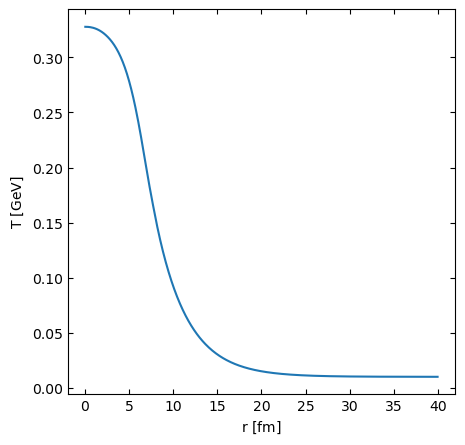

In [4]:
fields = Fluidum.initialize_fields(ent276, 0, 5; grid_params, initial_params);
#print(typeof(fields))
#eos = Heavy_Quark();
eos = FluiduMEoS();

plot_initial_field(fields; save=save_plots, path="Plots/initial_field_pce.png");

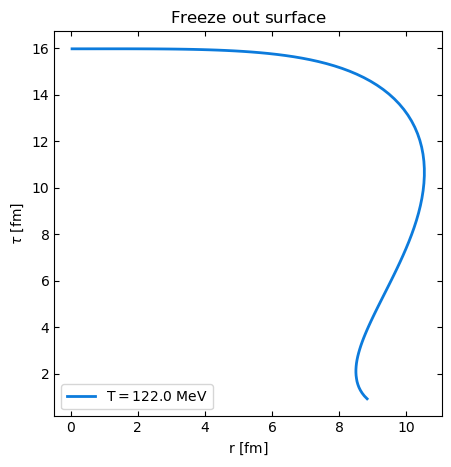

In [5]:
####################################zero diffusion
viscosity = QGPViscosity(2.0874/3.5,0.2); #or, ZeroViscosity();
bulk = SimpleBulkViscosity(0.017963,15.0); #or, ZeroBulkViscosity();

##########################no diffusion
diffusion = ZeroDiffusion();
params=Fluidum.FluidProperties(eos,viscosity,bulk,diffusion);
fo = freeze_out_routine(fields.discrete_field, Fluidum.matrxi1d_visc!_Tscale, params, fields.initial_field, tspan; Tfo = 0.1215);
plot_fo_surface(fo;save=save_plots);

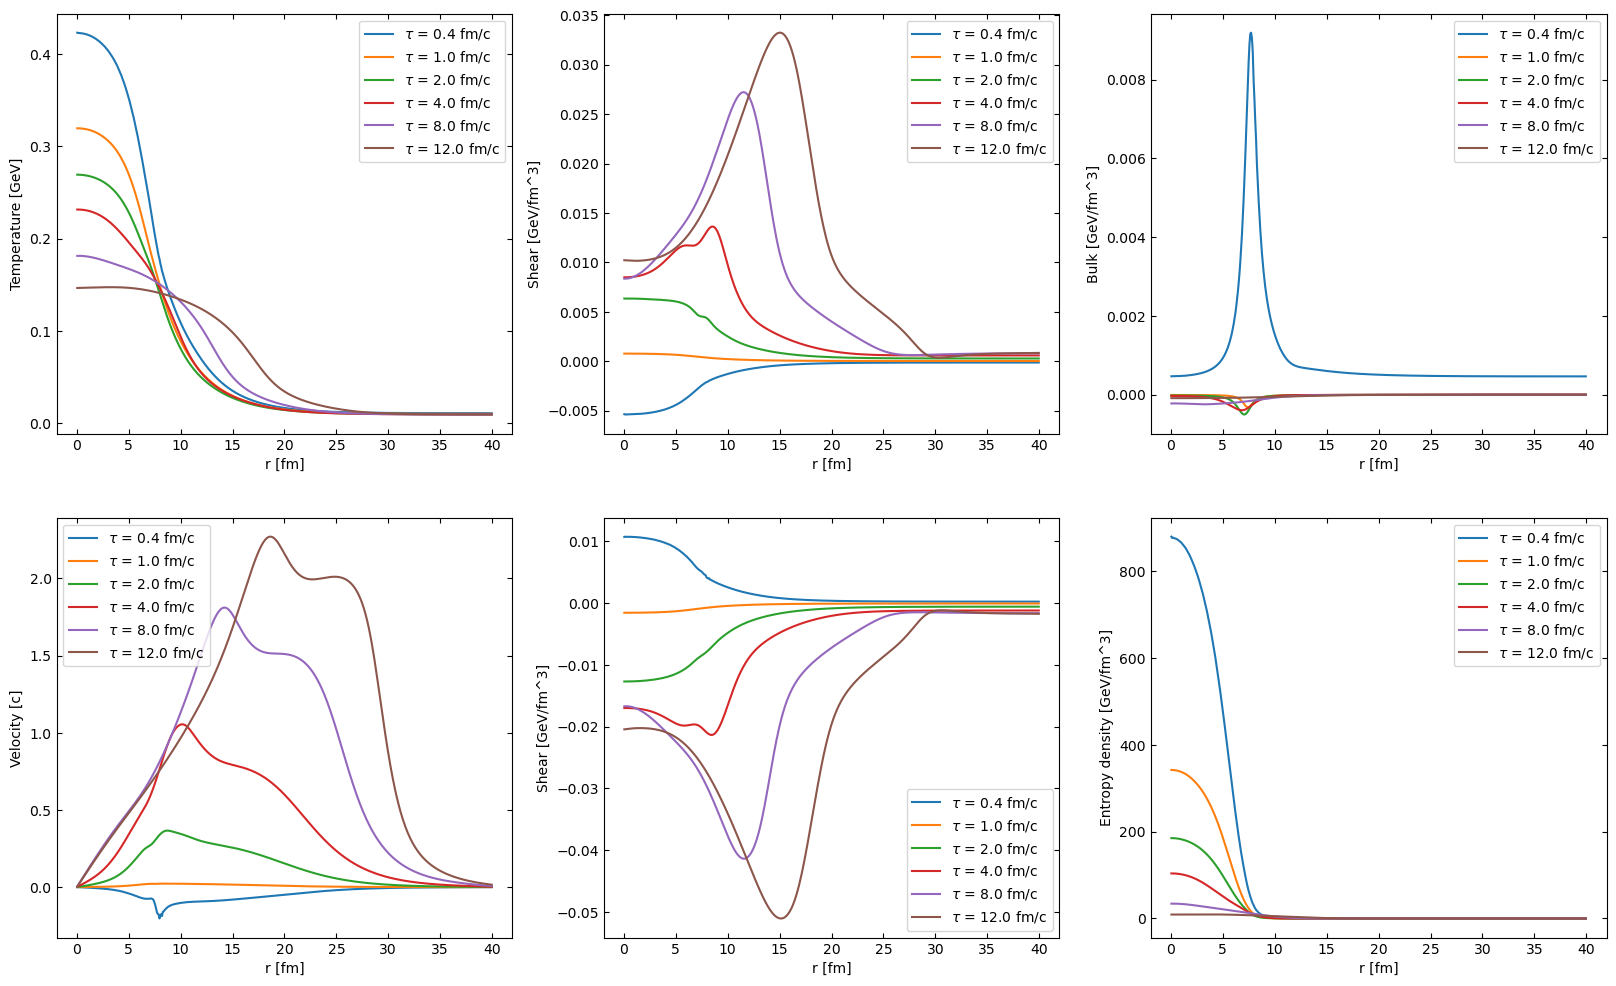

In [6]:
result_field = oneshoot(fields.discrete_field, Fluidum.matrxi1d_visc!, params, fields.initial_field, tspan; reltol = 1e-8);

times = [0.4, 1.0, 2.0, 4.0, 8.0, 12.0]
radius = zeros(gridpoints+2)
[radius[i]= disc.grid[i][1] for i in eachindex(disc.grid[1:end])] 

plot_result_fields(result_field, radius, times, params; save=save_plots);

Here begins my own plotting routine

In [28]:
include("Libs/data_lib.jl");

extraction_end_pion = 41; #number of data points to extract
filename_pion = "ExperimentalData/HEPData-ins1222333-v1-Table_1.csv"

data_pion = get_data(filename_pion, extraction_end_pion);
mult_pion_data = calculate_yield(data_pion; verbose=true);
mult_pion_data_excess = calculate_yield(data_pion; excess=true, verbose=true);
println("Pion data multiplicity (0.1 - 3.0 GeV/c): ", mult_pion_data[1], " +- ", mult_pion_data[2])
println("Pion data multiplicity (0.1 - 0.5 GeV/c): ", mult_pion_data_excess[1], " +- ", mult_pion_data_excess[2])

Yield: 682.1370916347523 + 0.46227961380718136 (stat) - 0.46227961380718136 (stat) + 11.575380312091593 (syst) - 11.575380312091593 (syst)
Yield: 682.1370916347523 ± 11.584607538060984 (total) + 11.584607538060984 (total) - 11.584607538060984 (total)

Yield: 397.03432248104536 + 0.3708293504388739 (stat) - 0.3708293504388739 (stat) + 10.904840995444424 (syst) - 10.904840995444424 (syst)
Yield: 397.03432248104536 ± 10.911144373670082 (total) + 10.911144373670082 (total) - 10.911144373670082 (total)

Pion data multiplicity (0.1 - 3.0 GeV/c): 682.1370916347523 +- 11.584607538060984
Pion data multiplicity (0.1 - 0.5 GeV/c): 397.03432248104536 +- 10.911144373670082


In [29]:
include("Libs/results_lib.jl");

#@show dic.pion
use_3d_kernel = false

results_pion_unhandled = get_results_list(fo, dic_cuts, params, data_pion.pt; interpolate_3d=use_3d_kernel);

### handling width study

In [30]:

results_pion_cuts = handle_f0_widths(results_pion_unhandled);

Starting indices for width considerations: [9, 28, 47, 66, 85, 104, 123]
Handling width considerations. Number of spectra before handling widths: 8
Handling width consideration starting at index: 9
Calculating mean spectra and multiplicities for lists 9 to 27
Handling width consideration starting at index: 28
Calculating mean spectra and multiplicities for lists 28 to 46
Handling width consideration starting at index: 47
Calculating mean spectra and multiplicities for lists 47 to 65
Handling width consideration starting at index: 66
Calculating mean spectra and multiplicities for lists 66 to 84
Handling width consideration starting at index: 85
Calculating mean spectra and multiplicities for lists 85 to 103
Handling width consideration starting at index: 104
Calculating mean spectra and multiplicities for lists 104 to 122
Handling width consideration starting at index: 123
Calculating mean spectra and multiplicities for lists 123 to 141
Done handling width considerations. Number of mea

### Possibly Rescaling

In [31]:
REFERENCE_MULT_TOTAL = 296.9204802282646
REFERENCE_MULT_THERMAL = 346.68494311992293

rescale_thermal::Bool = true;
rescale_total_refregion::Bool = true;

if rescale_thermal
    println("Rescaling to match all thermal spectra in (0.1 - 3.0 GeV/c) range, then match total spectra in (0.5 - 3.0 GeV/c) range.")
    rescaled_thermal_result_pion_cuts = rescale_result_list_thermal(results_pion_cuts; reference_mult = REFERENCE_MULT_THERMAL);
    if rescale_total_refregion
        println("Rescaling total result to match in (0.5 - 3.0 GeV/c) range.")
        rescaled_result_pion_cuts = rescale_result_list(rescaled_thermal_result_pion_cuts; reference_mult = REFERENCE_MULT_TOTAL); 
    else
        rescaled_result_pion_cuts = rescaled_thermal_result_pion_cuts;
    end
else
    if rescale_total_refregion
        println("Rescaling total result to match in (0.5 - 3.0 GeV/c) range.")
        rescaled_result_pion_cuts = rescale_result_list(results_pion_cuts; reference_mult = REFERENCE_MULT_TOTAL);
    else
        rescaled_result_pion_cuts = results_pion_cuts;
    end
end

Rescaling to match all thermal spectra in (0.1 - 3.0 GeV/c) range, then match total spectra in (0.5 - 3.0 GeV/c) range.
Reference thermal multiplicities (0.1 - 3.0 GeV/c): [346.68494311992293, 346.31709161090674, 346.8685405878683, 345.7950160387923, 347.26093998608127, 345.1580396399506, 347.51802879880063, 344.3931077011123, 345.2398783259241, 345.54862008567625, 344.9880861910483, 345.8156454001599, 344.71275909738733, 346.0436333620028, 344.41349454069854]
Scaling factors: [1.0, 1.0010621812146352, 0.9994707001458414, 1.0025735682697947, 0.9983413139808311, 1.0044237807166976, 0.9976027555124053, 1.0066547075640075, 1.0041856833023055, 1.0032884606338899, 1.0049185957335782, 1.0025137605291314, 1.0057212388299746, 1.0018532626989534, 1.006595120734899]
Rescaling total result to match in (0.5 - 3.0 GeV/c) range.
Reference multiplicities (0.5 - 3.0 GeV/c): [296.9204802282646, 312.83918052539883, 311.6840503052121, 313.6633146226509, 310.52492955563963, 314.4649494898037, 309.38743019

ResultsList([[(400.94178173921557, 0.005964256008713753), (391.01798946842484, 0.003743158679499592), (379.38222395623774, 0.003861861023407659), (364.3190311266163, 0.004521702848959613), (348.017210305952, 0.0026154081577798305), (317.02314329884706, 0.0015711724856826148), (271.9088563173381, 0.003261288507132032), (229.98067428044442, 0.0023604467225366577), (193.10731053442694, 0.0018218383930559412), (161.2293810925379, 0.0014652499808097685)  …  (0.7509791652866286, 1.090643266352711e-5), (0.568265699253122, 7.640544544694223e-6), (0.4124097683769914, 5.852078886436782e-6), (0.31149346156838614, 4.603253095403871e-6), (0.22396652426355426, 3.075612226733943e-6), (0.17293727390728605, 2.468270943453624e-6), (0.12190789424786112, 1.8069539580627947e-6), (0.09489012300544496, 1.3734144718246509e-6), (0.07183059823808323, 1.0078165509055579e-6), (0.048771145344515016, 6.995888939143453e-7)], [(400.86600401420907, 0.004188515371590373), (390.94787012950127, 0.00374929363756088), (379

## Look at Reference

Total uncertainties: ([210.34257771549724, 177.18069872308325, 158.11388300841898, 141.088624630053, 128.06248474865697, 60.521153326750145, 47.11528414431988, 37.91319031682773, 27.81150840928985, 21.311499243366246, 16.710774967068403, 9.912618221237011, 7.810249675906654, 6.711929677819934, 5.61426753904728, 4.601141162798638, 3.9706044879841658, 3.3309608223454084, 2.9091063920042526, 2.4399385238157127, 1.9701776569639602, 1.5546382215808283, 1.134416149391395, 0.8927485648266258, 0.6519202405202649, 0.4758571214135604, 0.35483094566286066, 0.26704681237565825, 0.20032473636573195, 0.15119854496654392, 0.11672617529928753, 0.0902551937563706, 0.07085795650454507, 0.05481204247243483, 0.04556237482836029, 0.03600472191254919, 0.029080061898145954, 0.02411057859114957, 0.01923460423299632, 0.01603277892319357, 0.013566502865514016], [210.34257771549724, 177.18069872308325, 158.11388300841898, 141.088624630053, 128.06248474865697, 60.521153326750145, 47.11528414431988, 37.91319031682

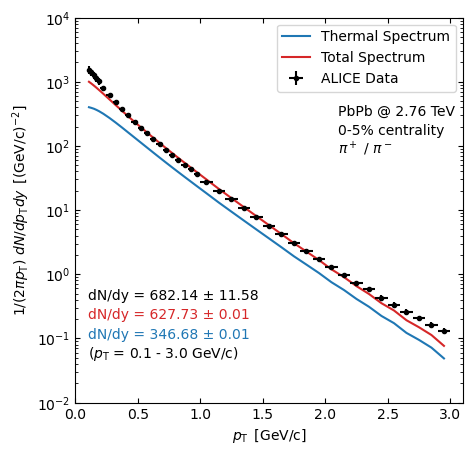

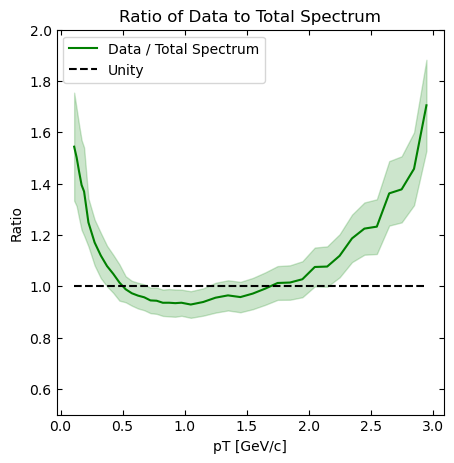

In [32]:
index = 1    # 1 : reference

test_reference = get_results_from_list_helper(rescaled_result_pion_cuts, index)

plot_spectra(test_reference, data_pion, mult_pion_data; save=save_plots)
plot_ratio(test_reference, data_pion; save = save_plots)

In [33]:
excess, excess_err_exp, excess_err_mod = calculate_excess(test_reference, mult_pion_data_excess)

println("Pion excess multiplicity (0.1 - 0.5 GeV/c) for 0-5% centrality: ", excess, " +- ", excess_err_exp, " (exp) +- ", excess_err_mod, " (model)")

Pion excess multiplicity (0.1 - 0.5 GeV/c) for 0-5% centrality: 66.22433719143106 +- 10.911144373670082 (exp) +- 5.000002427358482 (model)


### All samples

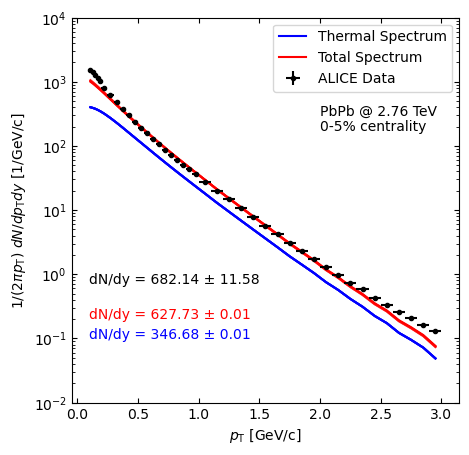

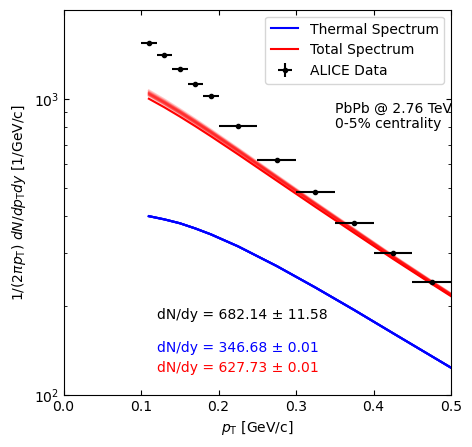

In [34]:
include("Libs/plotter_sampling.jl");

plot_sample_spectra(rescaled_result_pion_cuts, data_pion, mult_pion_data; save=save_plots)
plot_sample_spectra(rescaled_result_pion_cuts, data_pion, mult_pion_data; excess=true, save=save_plots)

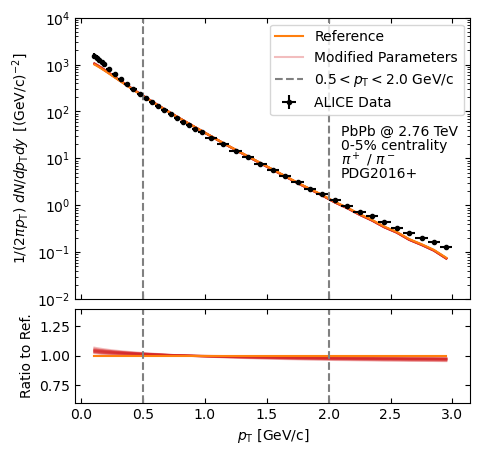

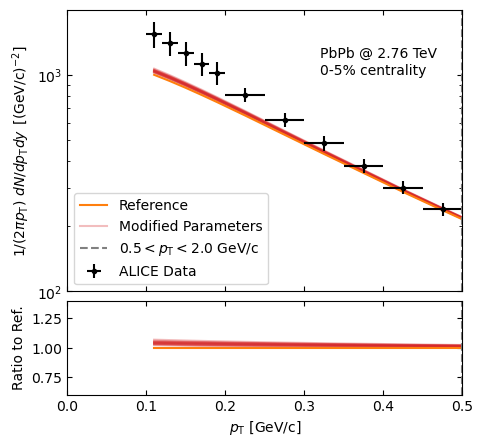

In [35]:
plot_sample_spectra_relative(rescaled_result_pion_cuts, data_pion, mult_pion_data; save=save_plots)
plot_sample_spectra_relative(rescaled_result_pion_cuts, data_pion, mult_pion_data; excess=true, save=save_plots)

### Specific plotting routines for f0

length excess1: 6 length excess2: 6
Mean Excess: 58.361372221162256 ± 3.633306084379223


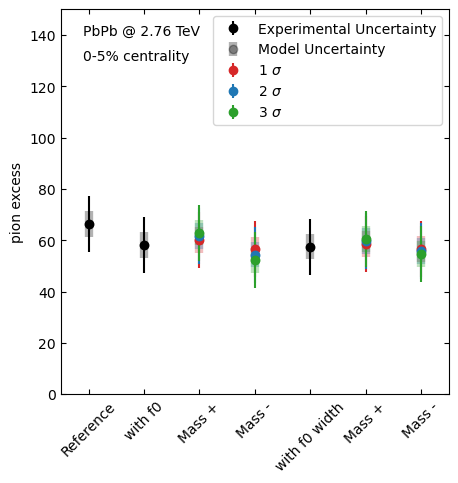

In [68]:
include("Libs/plotter_f0.jl");
excess, excess_err_exp, excess_err_mod = calculate_excess_list(rescaled_result_pion_cuts, mult_pion_data_excess)

plot_excess_f0(excess, excess_err_exp, excess_err_mod; nsigma=true, edge=true, save=save_plots)

length excess1: 6 length excess2: 6
Mean relative Excess: 0.08555666146419086 ± 0.005326357603091113


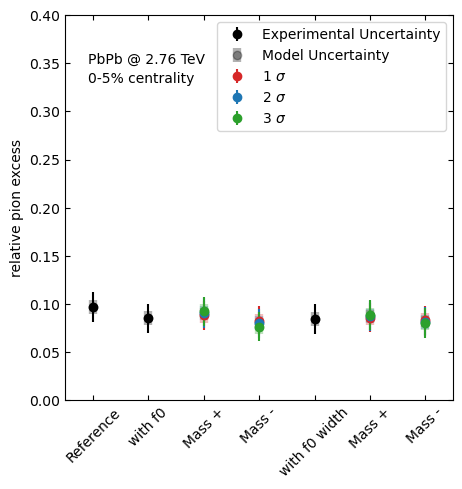

In [69]:
rel_excess, rel_excess_err_exp, rel_excess_err_mod = calculate_rel_excess_list(rescaled_result_pion_cuts, mult_pion_data, mult_pion_data_excess)

plot_rel_excess_f0(rel_excess, rel_excess_err_exp, rel_excess_err_mod; nsigma=true, edge=true, save=save_plots)

length excess1: 6 length excess2: 6
Mean relative Excess: 0.08555666146419086 ± 0.005326357603091113


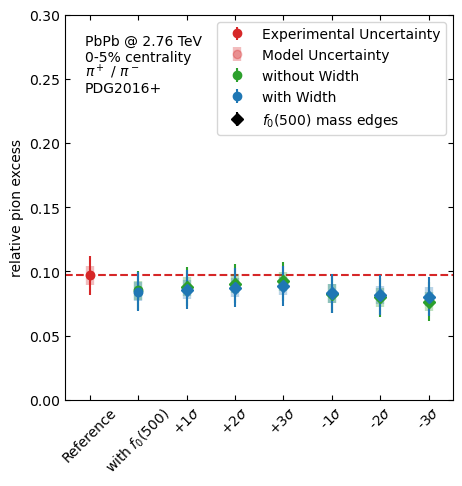

In [70]:
plot_rel_excess_f0_colors(rel_excess, rel_excess_err_exp, rel_excess_err_mod; nsigma=true, edge=true, save=save_plots)

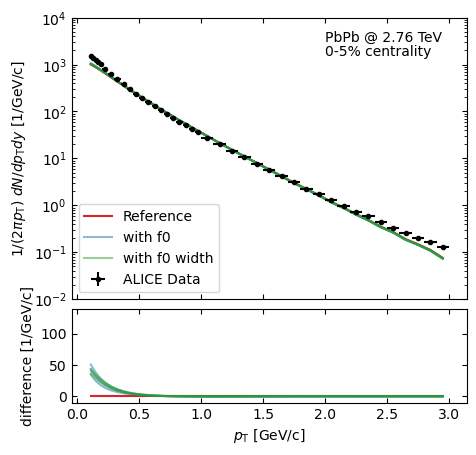

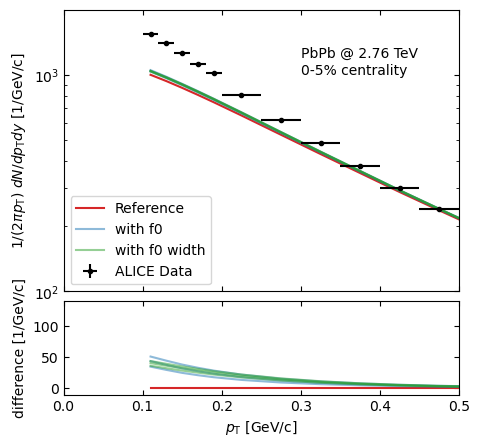

In [18]:
plot_sample_spectra_difference(rescaled_result_pion_cuts, data_pion, mult_pion_data; save=save_plots)
plot_sample_spectra_difference(rescaled_result_pion_cuts, data_pion, mult_pion_data; excess=true, save=save_plots)

Multiplicity for with f0 scaled by 7.4795: 688.4407215518216
Multiplicity for with f0 width scaled by 7.4795: 692.977591688916
Multiplicity for with f0 scaled by 7.4795: 688.4407215518216
Multiplicity for with f0 width scaled by 7.4795: 692.977591688916


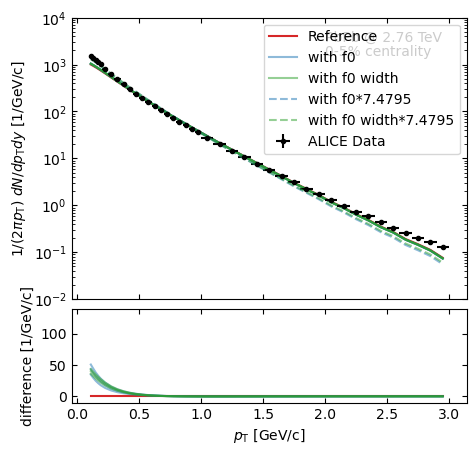

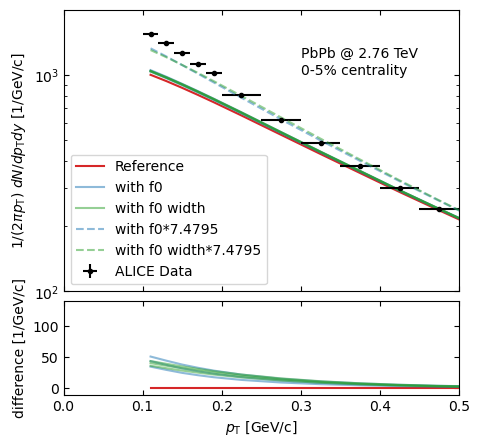

In [19]:
scaling_factor = 7.4795
plot_sample_spectra_difference_scaled(rescaled_result_pion_cuts, data_pion, scaling_factor; save=save_plots)
plot_sample_spectra_difference_scaled(rescaled_result_pion_cuts, data_pion, scaling_factor; excess=true, save=save_plots)

length excess1: 6 length excess2: 6
Mean relative Excess: 1.0125270307040022 ± 0.005787949650832228


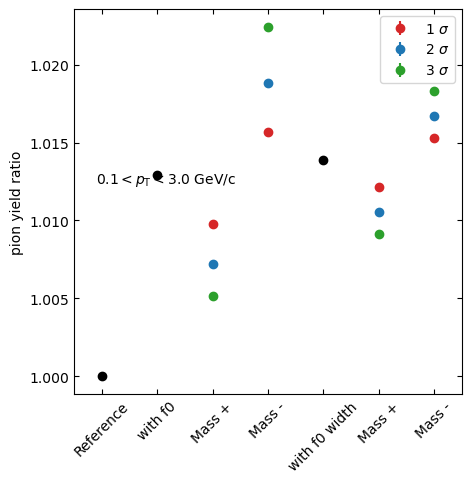

In [20]:
ratio, ratio_err = calculate_yield_ratio_list(rescaled_result_pion_cuts)

plot_yield_ratio_f0(ratio, ratio_err; nsigma=true, edge=true, save=save_plots)

In [21]:
# mean_pT_list, mean_pT_err_list = mean_pt_spectra_list(results_pion_cuts.spectra_total, data_pion.pt, data_pion.ptp, data_pion.ptm)
# plot_mean_pT(mean_pT_list, mean_pT_err_list; nsigma=true, edge=true, save=save_plots)
# println(mean_pT_err_list)

### Specific plotting routines for unhandled width list

In [22]:
results_pion_cuts = results_pion_unhandled;

REFERENCE_MULT_TOTAL = 296.9204802282646
REFERENCE_MULT_THERMAL = 346.68494311992293

if rescale_thermal
    println("Rescaling to match all thermal spectra in (0.1 - 3.0 GeV/c) range, then match total spectra in (0.5 - 3.0 GeV/c) range.")
    rescaled_thermal_result_pion_cuts = rescale_result_list_thermal(results_pion_cuts; reference_mult = REFERENCE_MULT_THERMAL);
    if rescale_total_refregion
        println("Rescaling total result to match in (0.5 - 3.0 GeV/c) range.")
        rescaled_result_pion_cuts = rescale_result_list(rescaled_thermal_result_pion_cuts; reference_mult = REFERENCE_MULT_TOTAL); 
    else
        rescaled_result_pion_cuts = rescaled_thermal_result_pion_cuts;
    end
else
    if rescale_total_refregion
        println("Rescaling total result to match in (0.5 - 3.0 GeV/c) range.")
        rescaled_result_pion_cuts = rescale_result_list(results_pion_cuts; reference_mult = REFERENCE_MULT_TOTAL);
    else
        rescaled_result_pion_cuts = results_pion_cuts;
    end
end

Rescaling to match all thermal spectra in (0.1 - 3.0 GeV/c) range, then match total spectra in (0.5 - 3.0 GeV/c) range.
Reference thermal multiplicities (0.1 - 3.0 GeV/c): [346.68494311992293, 346.31709161090674, 346.8685405878683, 345.7950160387923, 347.26093998608127, 345.1580396399506, 347.51802879880063, 344.3931077011123, 337.42842520617995, 339.60672122467207, 341.2719699689582, 342.635168581352, 343.7826317907393, 344.75845737352773, 345.5861388225351, 346.2782018835959, 346.8392918736588, 347.2692652462941, 347.5638183826219, 347.71687477762237, 347.7225790562851, 347.5797610436511, 347.3005514656676, 346.9247321726927, 346.54300698867905, 346.3194755466626, 346.43061678716145, 338.0793328462691, 340.4200277003067, 342.1240899454371, 343.46062952953014, 344.5417614114372, 345.4261508976495, 346.1472182074939, 346.72447565516103, 347.1689938117871, 347.485620035528, 347.6756757424119, 347.73848432843096, 347.67387541410676, 347.48618989644507, 347.19177769824927, 346.83186759165

ResultsList([[(400.94178173921557, 0.005964256008713753), (391.01798946842484, 0.003743158679499592), (379.38222395623774, 0.003861861023407659), (364.3190311266163, 0.004521702848959613), (348.017210305952, 0.0026154081577798305), (317.02314329884706, 0.0015711724856826148), (271.9088563173381, 0.003261288507132032), (229.98067428044442, 0.0023604467225366577), (193.10731053442694, 0.0018218383930559412), (161.2293810925379, 0.0014652499808097685)  …  (0.7509791652866286, 1.090643266352711e-5), (0.568265699253122, 7.640544544694223e-6), (0.4124097683769914, 5.852078886436782e-6), (0.31149346156838614, 4.603253095403871e-6), (0.22396652426355426, 3.075612226733943e-6), (0.17293727390728605, 2.468270943453624e-6), (0.12190789424786112, 1.8069539580627947e-6), (0.09489012300544496, 1.3734144718246509e-6), (0.07183059823808323, 1.0078165509055579e-6), (0.048771145344515016, 6.995888939143453e-7)], [(400.86600401420907, 0.004188515371590373), (390.94787012950127, 0.00374929363756088), (379

Starting indices for width considerations: [9, 28, 47, 66, 85, 104, 123]
Handling width considerations. Number of spectra before handling widths: 8
Handling width consideration starting at index: 9
Calculating mean spectra and multiplicities for lists 9 to 27
Handling width consideration starting at index: 28
Calculating mean spectra and multiplicities for lists 28 to 46
Handling width consideration starting at index: 47
Calculating mean spectra and multiplicities for lists 47 to 65
Handling width consideration starting at index: 66
Calculating mean spectra and multiplicities for lists 66 to 84
Handling width consideration starting at index: 85
Calculating mean spectra and multiplicities for lists 85 to 103
Handling width consideration starting at index: 104
Calculating mean spectra and multiplicities for lists 104 to 122
Handling width consideration starting at index: 123
Calculating mean spectra and multiplicities for lists 123 to 141
Done handling width considerations. Number of mea

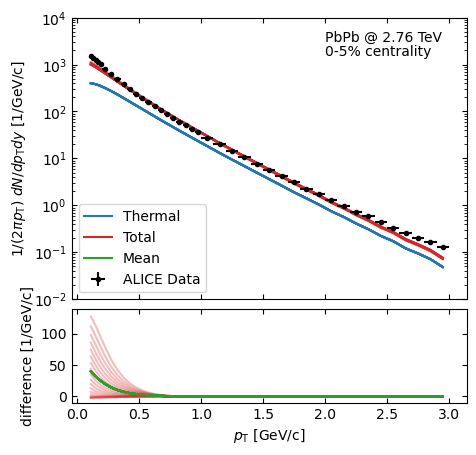

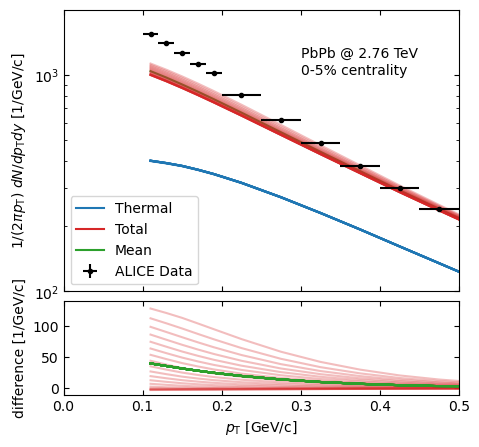

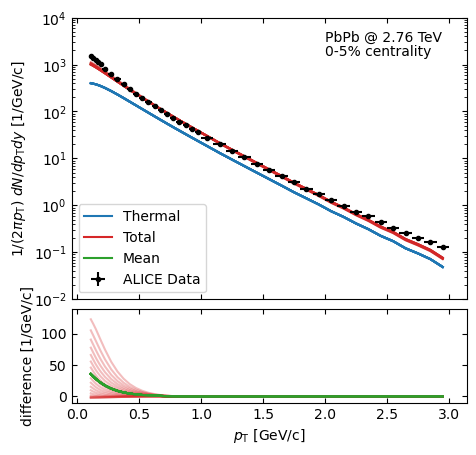

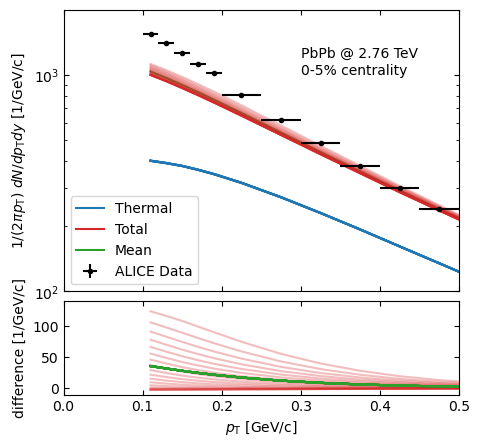

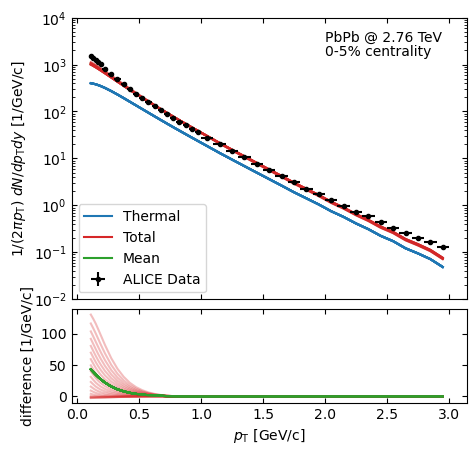

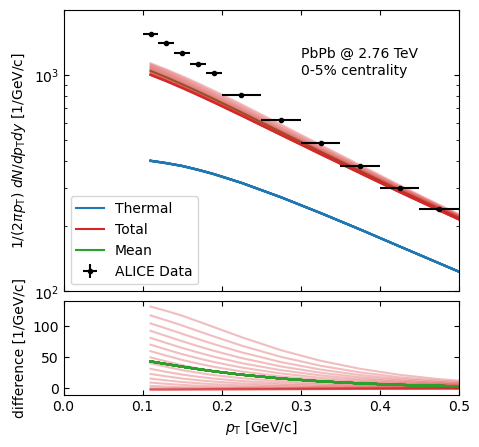

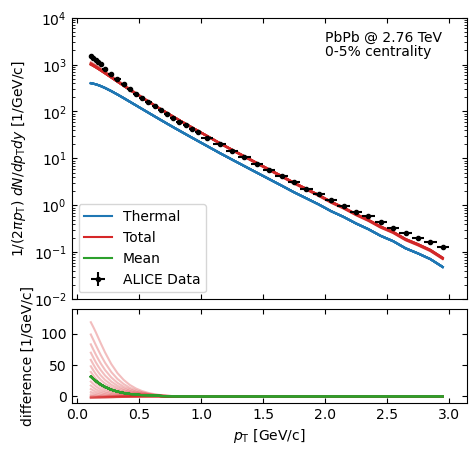

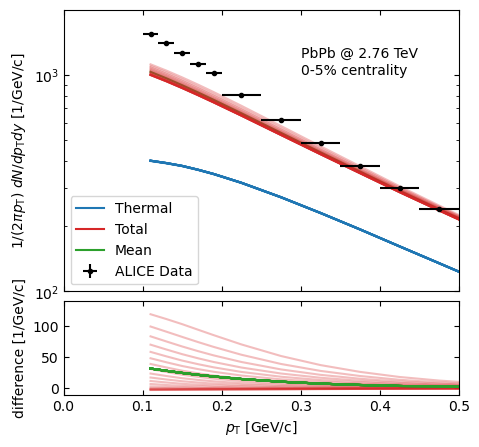

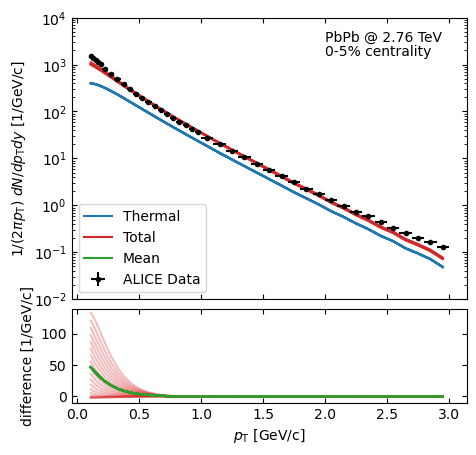

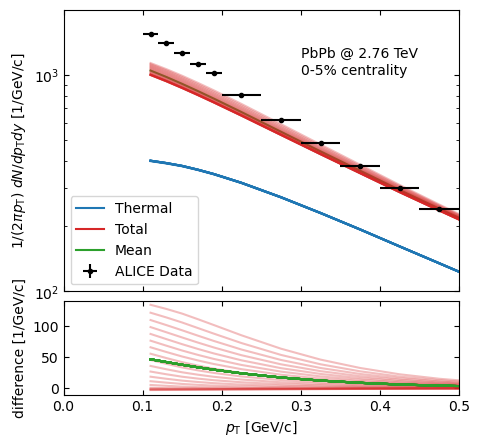

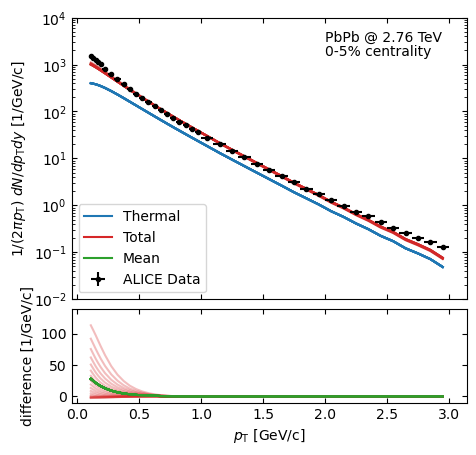

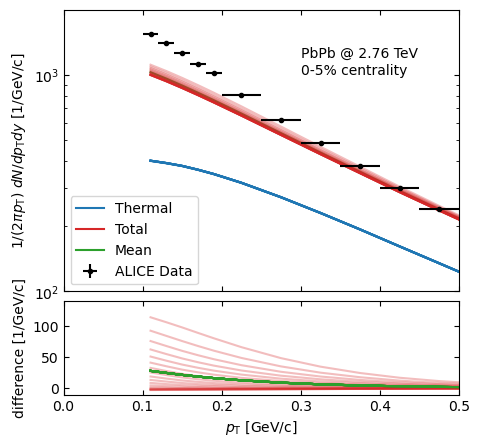

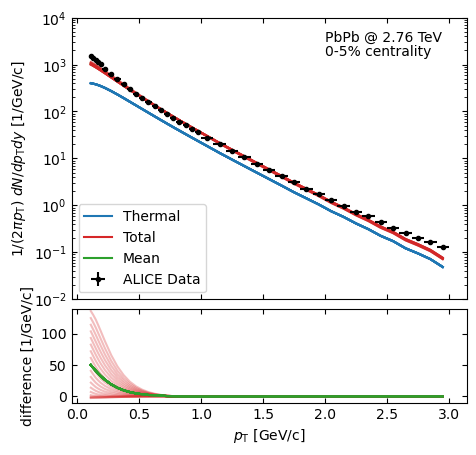

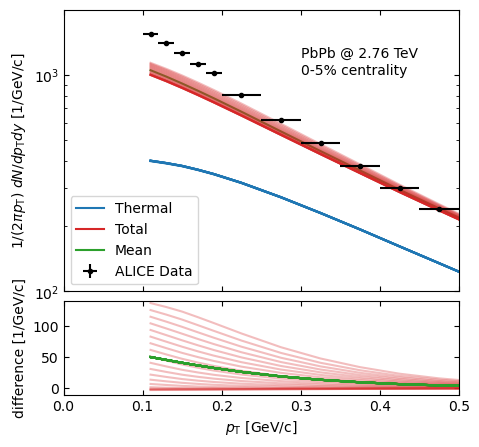

In [23]:
include("Libs/plotter_f0.jl");

for i in 0:6
    index = i # 0: reference  1: +1 sigma  2: -1 sigma 3: +2 sigma 4: -2 sigma 5: +3 sigma 6: -3 sigma
    plot_width_spectra_difference(rescaled_result_pion_cuts, data_pion, index; save=save_plots)
    plot_width_spectra_difference(rescaled_result_pion_cuts, data_pion, index; excess=true, save=save_plots)
end